# Лабораторная работа №3. Решающее дерево

Наборы данных, разбиение и метрики - как в ЛР1 (обоснование - в `LR1_knn.ipynb`):
классификация тональности отзывов на аниме (**macro-F1**, accuracy) и регрессия влияния финансовой новости
(**MAE**, RMSE, R2).

### Общие функции
Загрузка и разбиение данных, очистка текста, LSA-признаки, метаданные новостей, метрики и сохранение результатов. Эта ячейка одинакова во всех ЛР, чтобы разбиение train/test и метрики совпадали.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd().parent  # ноутбук запускается из labs/
DATA = ROOT / "data"
RESULTS = Path.cwd() / "results"
CACHE = DATA / "cache"
SEED = 42

# Имена признаков (заполняются при построении признаков) - для графиков важности
FEATURE_NAMES = {}
STAT_NAMES = ["log_len", "log_words", "excl_%", "quest_%", "smile_balance_%"]

CLASSES = ["Отрицательный", "Нейтральный", "Положительный"]


def clean_text(s: str) -> str:
    """Нижний регистр, удаление смайлов вида :lonely:, ссылок и лишних пробелов."""
    s = str(s).lower().replace("ё", "е")
    s = re.sub(r":[a-z_]+:", " ", s)
    s = re.sub(r"https?://\S+", " ", s)
    s = re.sub(r"\s+", " ", s)
    return s.strip()


def load_anime():
    """Отзывы на аниме -> (тексты train, тексты test, y train, y test). y: 0/1/2 = отр/нейтр/пол."""
    df = pd.read_csv(DATA / "anime" / "Anime_reviews_RU.csv", index_col=0).dropna(subset=["Text"])
    y = df["Rate"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
    X = df["Text"].map(clean_text).to_numpy()
    return train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)


def load_finnews():
    """Финансовые новости -> (df train, df test, y train, y test).

    Колонка reasoning исключается: это объяснение оценки, сгенерированное вместе с answer,
    т.е. прямая утечка целевой переменной.
    """
    df = pd.read_csv(DATA / "finnews" / "data.csv", index_col=0)
    df["text"] = df["article_text"].map(clean_text)
    y = df["answer"].to_numpy(dtype=float)
    X = df[["text", "sphere", "source", "date"]].reset_index(drop=True)
    return train_test_split(X, y, test_size=0.2, random_state=SEED)


def text_stats(texts) -> np.ndarray:
    """Простые числовые признаки текста: длина, число слов, доля '!', '?', заглавных скобок-смайлов."""
    rows = []
    for t in texts:
        n = max(len(t), 1)
        rows.append([np.log1p(len(t)), np.log1p(len(t.split())), t.count("!") / n * 100,
                     t.count("?") / n * 100, (t.count(")") - t.count("(")) / n * 100])
    return np.array(rows)


def svd_features(train_texts, test_texts, name, n_components=200):
    """TF-IDF (слова 1-2 граммы) -> TruncatedSVD (LSA) + статистики текста. Кэшируется на диск."""
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / f"{name}_n{len(train_texts)}_svd{n_components}.npz"
    if path.exists():
        d = np.load(path)
        FEATURE_NAMES[name] = list(d["names"])
        return d["tr"], d["te"]
    tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100000, sublinear_tf=True)
    a, b = tfidf.fit_transform(train_texts), tfidf.transform(test_texts)
    svd = TruncatedSVD(n_components=n_components, random_state=SEED)
    tr = np.hstack([svd.fit_transform(a), text_stats(train_texts)])
    te = np.hstack([svd.transform(b), text_stats(test_texts)])
    # Имя LSA-компоненты = 3 слова/биграммы с наибольшим весом в ней (для интерпретации важности)
    vocab = tfidf.get_feature_names_out()
    names = [f"svd{i}: " + "/".join(vocab[np.argsort(-c)[:3]]) for i, c in enumerate(svd.components_)] + STAT_NAMES
    np.savez(path, tr=tr, te=te, names=np.array(names))
    FEATURE_NAMES[name] = names
    return tr, te


def finnews_meta(train_df, test_df):
    """One-hot сферы и источника + день недели публикации."""
    enc = OneHotEncoder(handle_unknown="ignore")
    cols = ["sphere", "source"]
    a = enc.fit_transform(train_df[cols]).toarray()
    b = enc.transform(test_df[cols]).toarray()
    wd = lambda d: pd.get_dummies(pd.to_datetime(d["date"]).dt.weekday).reindex(columns=range(7), fill_value=0).to_numpy(float)
    FEATURE_NAMES["meta"] = list(enc.get_feature_names_out(cols)) + [f"weekday_{i}" for i in range(7)]
    return np.hstack([a, wd(train_df)]), np.hstack([b, wd(test_df)])


def plot_importance(values, names, title, top=20, ax=None):
    """Горизонтальная диаграмма top-N признаков по важности."""
    s = pd.Series(np.asarray(values), index=list(names)).sort_values(ascending=False)[:top][::-1]
    ax = ax or plt.subplots(figsize=(7, 0.3 * top + 1))[1]
    s.plot.barh(ax=ax, title=title, color="#4C72B0")
    return s[::-1]


def stack(*mats):
    """Склейка разреженных/плотных матриц по признакам в CSR."""
    return sparse.hstack([sparse.csr_matrix(m) for m in mats]).tocsr()


def clf_metrics(y_true, y_pred) -> dict:
    """Классификация: macro-F1 (основная, классы несбалансированы) и accuracy."""
    return {"f1_macro": round(float(f1_score(y_true, y_pred, average="macro")), 4),
            "accuracy": round(float(accuracy_score(y_true, y_pred)), 4)}


def reg_metrics(y_true, y_pred) -> dict:
    """Регрессия: MAE (основная, в пунктах шкалы), RMSE и R2."""
    return {"mae": round(float(mean_absolute_error(y_true, y_pred)), 3),
            "rmse": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 3),
            "r2": round(float(r2_score(y_true, y_pred)), 4)}


def save_results(lab: str, results: dict):
    """Сохраняет метрики лабораторной в labs/results/<lab>.json для итогового ноутбука."""
    RESULTS.mkdir(exist_ok=True)
    (RESULTS / f"{lab}.json").write_text(json.dumps(results, ensure_ascii=False, indent=2))


def results_table(results: dict) -> pd.DataFrame:
    """Словарь {задача: {этап: метрики}} -> таблица."""
    return pd.DataFrame([{"задача": t, "этап": s, **m} for t, d in results.items() for s, m in d.items()])

In [2]:
# Структура для метрик: задача -> этап -> {метрика: значение}
res = {"classification": {}, "regression": {}}

In [3]:
# Деревья sklearn
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

In [4]:
# Загружаем оба набора с фиксированным разбиением train/test (80/20, seed=42) - одинаковым во всех ЛР
Xa_tr, Xa_te, ya_tr, ya_te = load_anime()       # отзывы: тексты и классы 0/1/2
Xf_tr, Xf_te, yf_tr, yf_te = load_finnews()     # новости: таблица (text, sphere, source, date) и оценка влияния
print("anime:", len(Xa_tr), len(Xa_te), " finnews:", len(Xf_tr), len(Xf_te))

anime: 58572 14643  finnews: 8268 2067


In [5]:
# Фолды кросс-валидации (только на train): стратифицированные для классификации
skf = StratifiedKFold(3, shuffle=True, random_state=SEED)
kf = KFold(3, shuffle=True, random_state=SEED)

## 2. Бейзлайн

TF-IDF (1000 слов) + `DecisionTreeClassifier()` / `DecisionTreeRegressor()` с параметрами по умолчанию -
дерево растёт до чистых листьев (без ограничения глубины).

In [6]:
# Бейзлайн-признаки для деревьев: TF-IDF по 1000 самых частых слов (деревья плохо работают с огромным
# разреженным словарём). Для собственных реализаций матрица переводится в плотную float32
vec_a = TfidfVectorizer(max_features=1000)
A_tr, A_te = vec_a.fit_transform(Xa_tr), vec_a.transform(Xa_te)
vec_f = TfidfVectorizer(max_features=1000)
F_tr, F_te = vec_f.fit_transform(Xf_tr["text"]), vec_f.transform(Xf_te["text"])
Ad_tr, Ad_te = A_tr.toarray().astype(np.float32), A_te.toarray().astype(np.float32)
Fd_tr, Fd_te = F_tr.toarray().astype(np.float32), F_te.toarray().astype(np.float32)

In [7]:
# Обучение деревьев по умолчанию и оценка на тесте; глубина/число листьев показывают степень переобучения
dt_c = DecisionTreeClassifier(random_state=SEED).fit(A_tr, ya_tr)
res["classification"]["baseline"] = clf_metrics(ya_te, dt_c.predict(A_te))
dt_r = DecisionTreeRegressor(random_state=SEED).fit(F_tr, yf_tr)
res["regression"]["baseline"] = reg_metrics(yf_te, dt_r.predict(F_te))
print("глубина/листья:", dt_c.get_depth(), dt_c.get_n_leaves(), "|", dt_r.get_depth(), dt_r.get_n_leaves())
res

глубина/листья: 122 12023 | 310 4775


{'classification': {'baseline': {'f1_macro': 0.3914, 'accuracy': 0.4027}},
 'regression': {'baseline': {'mae': 40.299, 'rmse': 55.451, 'r2': -0.6901}}}

## 3. Улучшение бейзлайна

### 3.1 Гипотезы
1. **H1 - ограничение сложности.** Дерево без ограничений запоминает обучающую выборку; ограничение
   `max_depth` и `min_samples_leaf` уменьшит дисперсию.
2. **H2 - плотные семантические признаки.** Отдельное слово - слабый признак, разбиения по нему покрывают мало
   объектов. Компоненты LSA агрегируют много слов, и дерево может разбивать по "темам"/тональности.
   Статистики текста (длина, "!", "?", смайлы-скобки) добавляют нелексический сигнал.
3. **H3 (регрессия) - метаданные** (сфера, источник, день недели).
4. **H4 - критерий разбиения** для регрессии: `absolute_error` вместо `squared_error` оптимизирует сразу MAE -
   проверим `friedman_mse`/`squared_error` и устойчивость.

In [8]:
# Признаки улучшенного бейзлайна: LSA (TF-IDF 1-2 граммы -> SVD-200) + 5 статистик текста;
# для новостей дополнительно метаданные (сфера, источник, день недели)
Sa_tr, Sa_te = svd_features(Xa_tr, Xa_te, "anime")
Sf_tr, Sf_te = svd_features(Xf_tr["text"], Xf_te["text"], "finnews")
Mf_tr, Mf_te = finnews_meta(Xf_tr, Xf_te)
SMf_tr, SMf_te = np.hstack([Sf_tr, Mf_tr]), np.hstack([Sf_te, Mf_te])
print(Sa_tr.shape, SMf_tr.shape)

(58572, 205) (8268, 218)


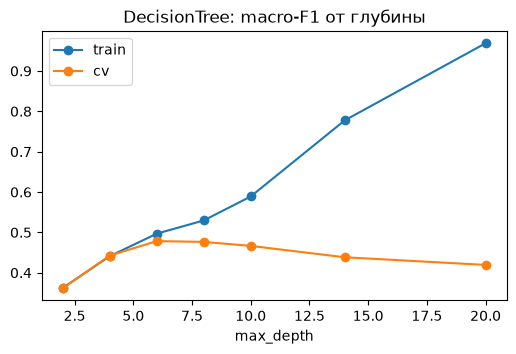

In [9]:
# H1: кривые валидации по глубине - train vs CV (на LSA-признаках), видно переобучение
depths = [2, 4, 6, 8, 10, 14, 20]
rows = []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    cv = cross_val_score(m, Sa_tr, ya_tr, cv=skf, scoring="f1_macro", n_jobs=-1).mean()
    tr = clf_metrics(ya_tr, m.fit(Sa_tr, ya_tr).predict(Sa_tr))["f1_macro"]
    rows.append({"max_depth": d, "train": tr, "cv": cv})
curve = pd.DataFrame(rows)
curve.plot(x="max_depth", y=["train", "cv"], marker="o", figsize=(6, 3.5), title="DecisionTree: macro-F1 от глубины")
plt.show()

In [10]:
# H1 + H2 для классификации: сетка (признаки x глубина x min_samples_leaf), CV macro-F1
rows = []
for rep, X in [("TF-IDF-1000", A_tr), ("LSA+stats", Sa_tr)]:
    for d in [6, 8, 10, 14]:
        for leaf in [10, 30, 100]:
            s = cross_val_score(DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=SEED),
                                X, ya_tr, cv=skf, scoring="f1_macro", n_jobs=-1).mean()
            rows.append({"rep": rep, "max_depth": d, "min_samples_leaf": leaf, "cv_f1": s})
cv_c = pd.DataFrame(rows)
cv_c.pivot_table(index=["max_depth", "min_samples_leaf"], columns="rep", values="cv_f1").round(4)

rep                         LSA+stats  TF-IDF-1000
max_depth min_samples_leaf                        
6         10                   0.4784       0.3495
          30                   0.4788       0.3500
          100                  0.4784       0.3507
8         10                   0.4764       0.3512
          30                   0.4752       0.3509
          100                  0.4779       0.3502
10        10                   0.4669       0.3987
          30                   0.4659       0.4003
          100                  0.4704       0.3981
14        10                   0.4387       0.4178
          30                   0.4510       0.4127
          100                  0.4692       0.4181

In [11]:
# H1 + H2 + H3 для регрессии: признаки (TF-IDF / LSA / LSA+meta) x глубина x min_samples_leaf, CV MAE
rows = []
for rep, X in [("TF-IDF-1000", F_tr), ("LSA+stats", Sf_tr), ("LSA+stats+meta", SMf_tr)]:
    for d in [4, 6, 8, 12]:
        for leaf in [10, 30, 100]:
            s = -cross_val_score(DecisionTreeRegressor(max_depth=d, min_samples_leaf=leaf, random_state=SEED),
                                 X, yf_tr, cv=kf, scoring="neg_mean_absolute_error", n_jobs=-1).mean()
            rows.append({"rep": rep, "max_depth": d, "min_samples_leaf": leaf, "cv_mae": s})
cv_r = pd.DataFrame(rows)
cv_r.pivot_table(index=["max_depth", "min_samples_leaf"], columns="rep", values="cv_mae").round(2)

rep                         LSA+stats  LSA+stats+meta  TF-IDF-1000
max_depth min_samples_leaf                                        
4         10                    33.66           33.47        34.01
          30                    33.63           33.60        34.04
          100                   33.60           33.62        34.00
6         10                    34.35           34.18        33.94
          30                    34.18           34.01        34.05
          100                   34.00           33.94        33.83
8         10                    35.28           34.98        34.06
          30                    35.27           34.75        34.14
          100                   34.34           34.38        33.85
12        10                    38.13           37.99        34.29
          30                    36.42           36.38        34.37
          100                   34.39           34.44        34.21

In [12]:
# H4: критерий разбиения регрессионного дерева при лучших найденных глубине/листе
best_r = cv_r.loc[cv_r["cv_mae"].idxmin()]
Xr_cv = {"TF-IDF-1000": F_tr, "LSA+stats": Sf_tr, "LSA+stats+meta": SMf_tr}[best_r["rep"]]
crit_cv = {}
for crit in ["squared_error", "friedman_mse", "absolute_error"]:
    m = DecisionTreeRegressor(criterion=crit, max_depth=int(best_r["max_depth"]), min_samples_leaf=int(best_r["min_samples_leaf"]), random_state=SEED)
    crit_cv[crit] = -cross_val_score(m, Xr_cv, yf_tr, cv=kf, scoring="neg_mean_absolute_error", n_jobs=-1).mean()
best_crit = min(crit_cv, key=crit_cv.get)
print({k: round(v, 3) for k, v in crit_cv.items()}, "-> лучший:", best_crit)

{'squared_error': np.float64(33.465), 'friedman_mse': np.float64(33.465), 'absolute_error': np.float64(32.848)} -> лучший: absolute_error


### 3.3-3.5 Улучшенный бейзлайн
Лучшие по CV признаки, гиперпараметры и критерий разбиения регрессионного дерева.

In [13]:
# Обучение улучшенных деревьев на всём train и оценка на тесте
best_c = cv_c.loc[cv_c["cv_f1"].idxmax()]
print(best_c.to_dict(), best_r.to_dict())
reps_c = {"TF-IDF-1000": (A_tr, A_te), "LSA+stats": (Sa_tr, Sa_te)}
reps_r = {"TF-IDF-1000": (F_tr, F_te), "LSA+stats": (Sf_tr, Sf_te), "LSA+stats+meta": (SMf_tr, SMf_te)}
Xc_tr, Xc_te = reps_c[best_c["rep"]]
Xr_tr, Xr_te = reps_r[best_r["rep"]]
pc = dict(max_depth=int(best_c["max_depth"]), min_samples_leaf=int(best_c["min_samples_leaf"]))
pr = dict(max_depth=int(best_r["max_depth"]), min_samples_leaf=int(best_r["min_samples_leaf"]))
dt_c2 = DecisionTreeClassifier(**pc, random_state=SEED).fit(Xc_tr, ya_tr)
res["classification"]["improved"] = clf_metrics(ya_te, dt_c2.predict(Xc_te))
dt_r2 = DecisionTreeRegressor(**pr, criterion=best_crit, random_state=SEED).fit(Xr_tr, yf_tr)
res["regression"]["improved"] = reg_metrics(yf_te, dt_r2.predict(Xr_te))
results_table(res)

{'rep': 'LSA+stats', 'max_depth': 6, 'min_samples_leaf': 30, 'cv_f1': 0.4787858315327005} {'rep': 'LSA+stats+meta', 'max_depth': 4, 'min_samples_leaf': 10, 'cv_mae': 33.46505238980075}


,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.3914,0.4027,NaN,NaN,NaN
1,classification,improved,0.4715,0.4857,NaN,NaN,NaN
2,regression,baseline,NaN,NaN,40.299,55.451,-0.6901
3,regression,improved,NaN,NaN,31.671,42.307,0.0162


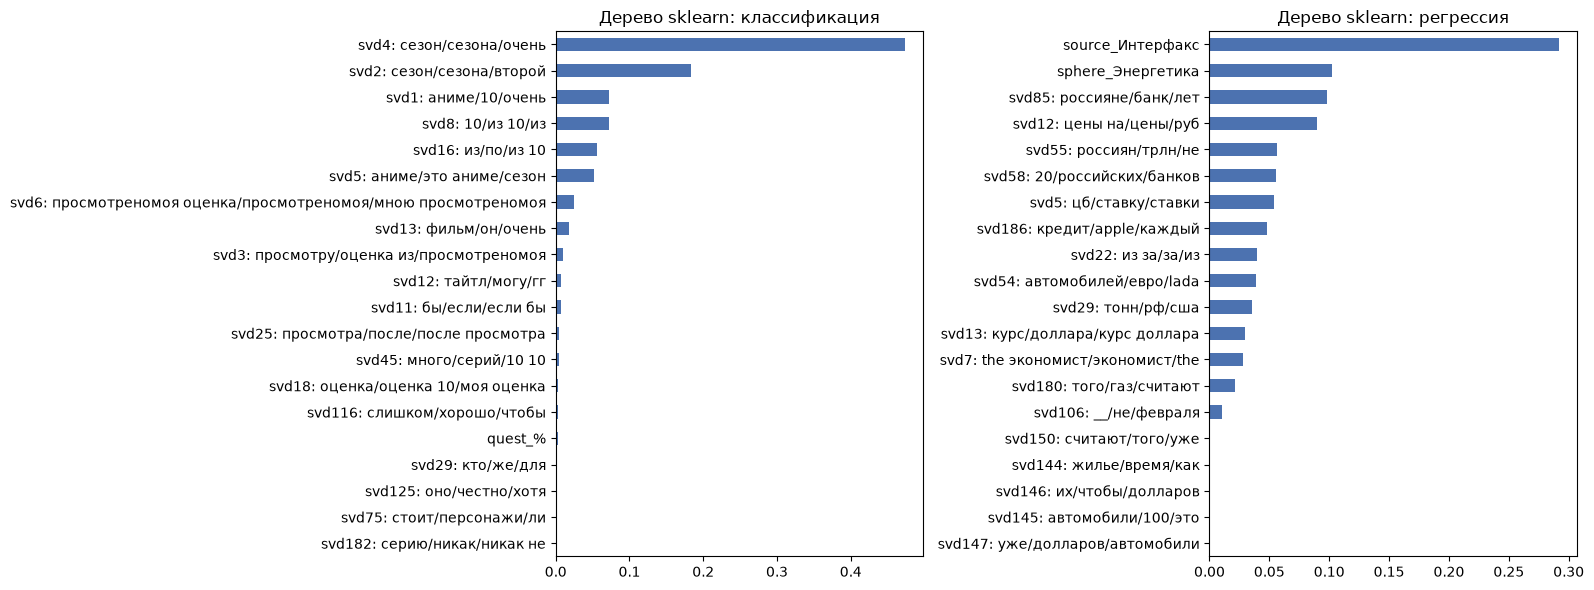

In [14]:
# Важность признаков улучшенных деревьев sklearn (суммарное уменьшение Джини / MSE в разбиениях по признаку).
# Имя LSA-компоненты - её 3 самых весомых слова
names_c = list(vec_a.get_feature_names_out()) if best_c["rep"] == "TF-IDF-1000" else FEATURE_NAMES["anime"]
names_r = {"TF-IDF-1000": list(vec_f.get_feature_names_out()), "LSA+stats": FEATURE_NAMES["finnews"],
           "LSA+stats+meta": FEATURE_NAMES["finnews"] + FEATURE_NAMES["meta"]}[best_r["rep"]]
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_importance(dt_c2.feature_importances_, names_c, "Дерево sklearn: классификация", ax=ax[0])
plot_importance(dt_r2.feature_importances_, names_r, "Дерево sklearn: регрессия", ax=ax[1])
plt.tight_layout(); plt.show()

### 3.7 Выводы по улучшению

- **H1 (ограничение сложности) подтверждена.** Дерево по умолчанию вырастает до глубины 122 (12 023 листа) для отзывов и 310 для новостей и сильно переобучается: в регрессии MAE 40.3 и R2 -0.69 - хуже константы. Кривая train/CV показывает, что CV-качество максимально на глубине ~6, дальше train растёт, а CV падает.
- **H2 (плотные признаки) подтверждена - самый сильный эффект для классификации:** на LSA+статистиках CV macro-F1 0.479 против <=0.418 на TF-IDF-1000. На отдельных словах дереву нужна большая глубина, чтобы что-то выучить; LSA-компоненты агрегируют тональность.
- **H3 (метаданные)** немного помогают регрессии: лучшая CV MAE 33.47 с метаданными против 33.60 без них.
- **H4 (критерий) подтверждена:** `absolute_error` даёт CV MAE 32.85 против 33.47 у `squared_error` - дерево с медианами в листьях напрямую оптимизирует MAE. Платой стал R2 (0.016 против 0.059): медиана хуже приближает среднее и сильнее ошибается на хвостах.
- Важность признаков: для отзывов дерево почти целиком опирается на 2 компоненты (лексика сезонов/сиквелов), дальше - "аниме/10/очень" и "10 из 10"; для новостей главные разбиения - по **метаданным** (источник "Интерфакс", сфера "Энергетика"), затем компоненты про банки, цены и ставки ЦБ.
- Итог: macro-F1 **0.391 -> 0.472**, MAE **40.30 -> 31.67**.

## 4. Собственная реализация решающего дерева (CART)

Реализация - в ячейке ниже (та же ячейка используется в ЛР4 для случайного леса и в ЛР5 для градиентного бустинга). Ключевые идеи:

- **Единый критерий.** Дерево минимизирует сумму квадратов отклонений (SSE) по всем выходам. Для регрессии это
  обычный MSE-критерий. Для классификации цель кодируется one-hot; уменьшение SSE по one-hot-векторам равно
  уменьшению **индекса Джини**, умноженного на число объектов, т.е. это ровно CART-классификатор,
  а значение листа - доли классов.
- **Гистограммный поиск порогов.** Каждый признак заранее разбивается на <=32 квантильных бина (`Binner`).
  В узле одной операцией `bincount` строятся гистограммы числа объектов и сумм целей по всем (признак, бин),
  кумулятивные суммы дают статистики левой/правой части для всех порогов сразу, выигрыш
  `gain = S_L**2 / n_L + S_R**2 / n_R - S**2 / n` считается векторно, выбирается максимум.
- Узлы хранятся в плоских массивах, предсказание - векторный спуск всех объектов одновременно.
- Параметры: `max_depth`, `min_samples_leaf`, `max_features` (для леса), `reg_lambda` и гессианы (для бустинга).

In [15]:
# Гистограммное решающее дерево CART (одинаковое в ЛР3-ЛР5)
import numpy as np


class Binner:
    """Переводит вещественные признаки в номера квантильных бинов (uint8)."""

    def __init__(self, n_bins=32):
        self.n_bins = n_bins

    def fit(self, X):
        qs = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        self.edges = [np.unique(np.quantile(X[:, j], qs)) for j in range(X.shape[1])]
        return self

    def transform(self, X):
        # code <= b  <=>  x <= edges[b]
        return np.stack([np.searchsorted(e, X[:, j], side="left") for j, e in enumerate(self.edges)],
                        axis=1).astype(np.uint8)


class HistTree:
    """Гистограммное дерево. G - цели/градиенты (n, K), H - гессианы (n, K) или None (=1).

    Значение листа = sum(G) / (sum(H) + reg_lambda); при H=1, lambda=0 это среднее.
    """

    def __init__(self, max_depth=8, min_samples_leaf=20, max_features=None, reg_lambda=0.0,
                 n_bins=32, random_state=None):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.reg_lambda = reg_lambda
        self.n_bins = n_bins
        self.rng = np.random.default_rng(random_state)

    def fit(self, X, G, H=None, binner=None, codes=None):
        G = np.asarray(G, dtype=float)
        if G.ndim == 1:
            G = G[:, None]
        H = np.ones_like(G) if H is None else np.asarray(H, dtype=float).reshape(G.shape)
        self.binner = binner or Binner(self.n_bins).fit(X)
        C = codes if codes is not None else self.binner.transform(X)
        n, F = C.shape
        self.B = max(len(e) for e in self.binner.edges) + 1
        offsets = (np.arange(F) * self.B).astype(np.int64)
        # max_features: None - все признаки, float - доля, int - количество (случайно в каждом узле)
        mf = self.max_features
        k_feat = F if mf is None else max(1, int(mf * F)) if isinstance(mf, float) else int(mf)
        max_depth = np.inf if self.max_depth is None else self.max_depth

        # Узлы хранятся в плоских списках: признак, порог, левый/правый потомок, значение листа
        self.feat, self.thr, self.left, self.right, self.value = [], [], [], [], []
        # Важность признака = суммарное уменьшение SSE (для классификации - Джини) в его разбиениях
        self.importances_ = np.zeros(F)

        def new_node(idx):
            self.feat.append(-1); self.thr.append(0.0); self.left.append(-1); self.right.append(-1)
            self.value.append(G[idx].sum(0) / (H[idx].sum(0) + self.reg_lambda))
            return len(self.feat) - 1

        stack = [(np.arange(n), new_node(np.arange(n)), 0)]
        while stack:
            idx, node, depth = stack.pop()
            m = len(idx)
            if depth >= max_depth or m < 2 * self.min_samples_leaf:
                continue
            feats = np.arange(F) if k_feat >= F else np.sort(self.rng.choice(F, k_feat, replace=False))
            flat = (C[idx][:, feats].astype(np.int64) + offsets[: len(feats)]).ravel()
            size = len(feats) * self.B
            # Гистограммы: число объектов и суммы целей в каждом (признак, бин)
            cnt = np.bincount(flat, minlength=size).reshape(len(feats), self.B)
            g = G[idx]
            sums = np.stack([np.bincount(flat, weights=np.repeat(g[:, k], len(feats)), minlength=size)
                             .reshape(len(feats), self.B) for k in range(g.shape[1])], axis=-1)
            # Накопленные суммы = статистики левой части для порога "бин <= b"
            nL = np.cumsum(cnt, axis=1)[:, :-1]
            SL = np.cumsum(sums, axis=1)[:, :-1]
            S = g.sum(0)
            nR = m - nL
            SR = S - SL
            with np.errstate(divide="ignore", invalid="ignore"):
                gain = (SL ** 2).sum(-1) / nL + (SR ** 2).sum(-1) / nR - (S ** 2).sum() / m
            gain[(nL < self.min_samples_leaf) | (nR < self.min_samples_leaf)] = -np.inf
            gain = np.nan_to_num(gain, nan=-np.inf)
            fi, b = np.unravel_index(np.argmax(gain), gain.shape)
            if not np.isfinite(gain[fi, b]) or gain[fi, b] <= 1e-12:
                continue
            f = feats[fi]
            self.importances_[f] += gain[fi, b]
            mask = C[idx, f] <= b
            self.feat[node] = int(f)
            self.thr[node] = float(self.binner.edges[f][b])
            li, ri = idx[mask], idx[~mask]
            self.left[node], self.right[node] = new_node(li), new_node(ri)
            stack.append((li, self.left[node], depth + 1))
            stack.append((ri, self.right[node], depth + 1))

        self.feat, self.thr = np.array(self.feat), np.array(self.thr)
        self.left, self.right = np.array(self.left), np.array(self.right)
        self.value = np.array(self.value)
        return self

    def predict_raw(self, X):
        """Спуск всех объектов по дереву одновременно (векторно по уровням)."""
        node = np.zeros(len(X), dtype=np.int64)
        active = self.feat[node] >= 0
        while active.any():
            a = np.where(active)[0]
            nd = node[a]
            go_left = X[a, self.feat[nd]] <= self.thr[nd]
            node[a] = np.where(go_left, self.left[nd], self.right[nd])
            active[a] = self.feat[node[a]] >= 0
        return self.value[node]

    @property
    def feature_importances_(self):
        return self.importances_ / max(self.importances_.sum(), 1e-12)

    @property
    def n_leaves(self):
        return int((self.feat < 0).sum())


class MyDecisionTreeClassifier:
    """Классификатор: дерево на one-hot целях, предсказание - класс с максимальной долей в листе."""

    def __init__(self, **kw):
        self.kw = kw

    def fit(self, X, y, **fit_kw):
        self.classes_ = np.unique(y)
        Y = (y[:, None] == self.classes_[None, :]).astype(float)
        self.tree_ = HistTree(**self.kw).fit(X, Y, **fit_kw)
        return self

    def predict_proba(self, X):
        return self.tree_.predict_raw(X)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]


class MyDecisionTreeRegressor:
    """Регрессор: значение листа - среднее целевой переменной."""

    def __init__(self, **kw):
        self.kw = kw

    def fit(self, X, y, **fit_kw):
        self.tree_ = HistTree(**self.kw).fit(X, y, **fit_kw)
        return self

    def predict(self, X):
        return self.tree_.predict_raw(X)[:, 0]

In [16]:
# Проверка корректности на улучшенных признаках: качество близко к sklearn при тех же ограничениях
chk = MyDecisionTreeClassifier(max_depth=6, min_samples_leaf=30).fit(Sa_tr, ya_tr)
print("my:", clf_metrics(ya_te, chk.predict(Sa_te)),
      " sklearn:", clf_metrics(ya_te, DecisionTreeClassifier(max_depth=6, min_samples_leaf=30).fit(Sa_tr, ya_tr).predict(Sa_te)))

my: {'f1_macro': 0.469, 'accuracy': 0.4905}  sklearn: {'f1_macro': 0.4715, 'accuracy': 0.4857}


### 4.2-4.3 Собственная реализация с параметрами бейзлайна
TF-IDF (1000 слов), дерево без ограничения глубины, `min_samples_leaf=1`.

In [17]:
# Обучение и оценка собственного дерева в конфигурации бейзлайна
my_c = MyDecisionTreeClassifier(max_depth=None, min_samples_leaf=1).fit(Ad_tr, ya_tr)
res["classification"]["custom"] = clf_metrics(ya_te, my_c.predict(Ad_te))
my_r = MyDecisionTreeRegressor(max_depth=None, min_samples_leaf=1).fit(Fd_tr, yf_tr)
res["regression"]["custom"] = reg_metrics(yf_te, my_r.predict(Fd_te))
print("листья:", my_c.tree_.n_leaves, my_r.tree_.n_leaves)
results_table({t: {s: d[s] for s in ["baseline", "custom"]} for t, d in res.items()})

листья: 13351 5121


,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.3914,0.4027,NaN,NaN,NaN
1,classification,custom,0.3930,0.4033,NaN,NaN,NaN
2,regression,baseline,NaN,NaN,40.299,55.451,-0.6901
3,regression,custom,NaN,NaN,40.291,55.351,-0.6840


### 4.5 Выводы

Собственное гистограммное CART-дерево без ограничений даёт практически те же метрики, что и sklearn (macro-F1 0.393 против 0.391, MAE 40.29 против 40.30). Небольшие отличия объясняются бинированием порогов (<=32 квантильных бина вместо всех уникальных значений). Неограниченное дерево плохо работает в любой реализации - проблема в переобучении, а не в коде.

### 4.6-4.8 Собственная реализация + техники улучшенного бейзлайна

In [18]:
# Собственное дерево на признаках улучшенного бейзлайна с подобранными max_depth / min_samples_leaf
dense = lambda X: X.toarray() if hasattr(X, "toarray") else X
my_c2 = MyDecisionTreeClassifier(**pc).fit(dense(Xc_tr), ya_tr)
res["classification"]["custom_improved"] = clf_metrics(ya_te, my_c2.predict(dense(Xc_te)))
my_r2 = MyDecisionTreeRegressor(**pr).fit(dense(Xr_tr), yf_tr)
res["regression"]["custom_improved"] = reg_metrics(yf_te, my_r2.predict(dense(Xr_te)))
results_table({t: {s: d[s] for s in ["improved", "custom_improved"]} for t, d in res.items()})

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,improved,0.4715,0.4857,NaN,NaN,NaN
1,classification,custom_improved,0.4690,0.4905,NaN,NaN,NaN
2,regression,improved,NaN,NaN,31.671,42.307,0.0162
3,regression,custom_improved,NaN,NaN,32.469,41.458,0.0553


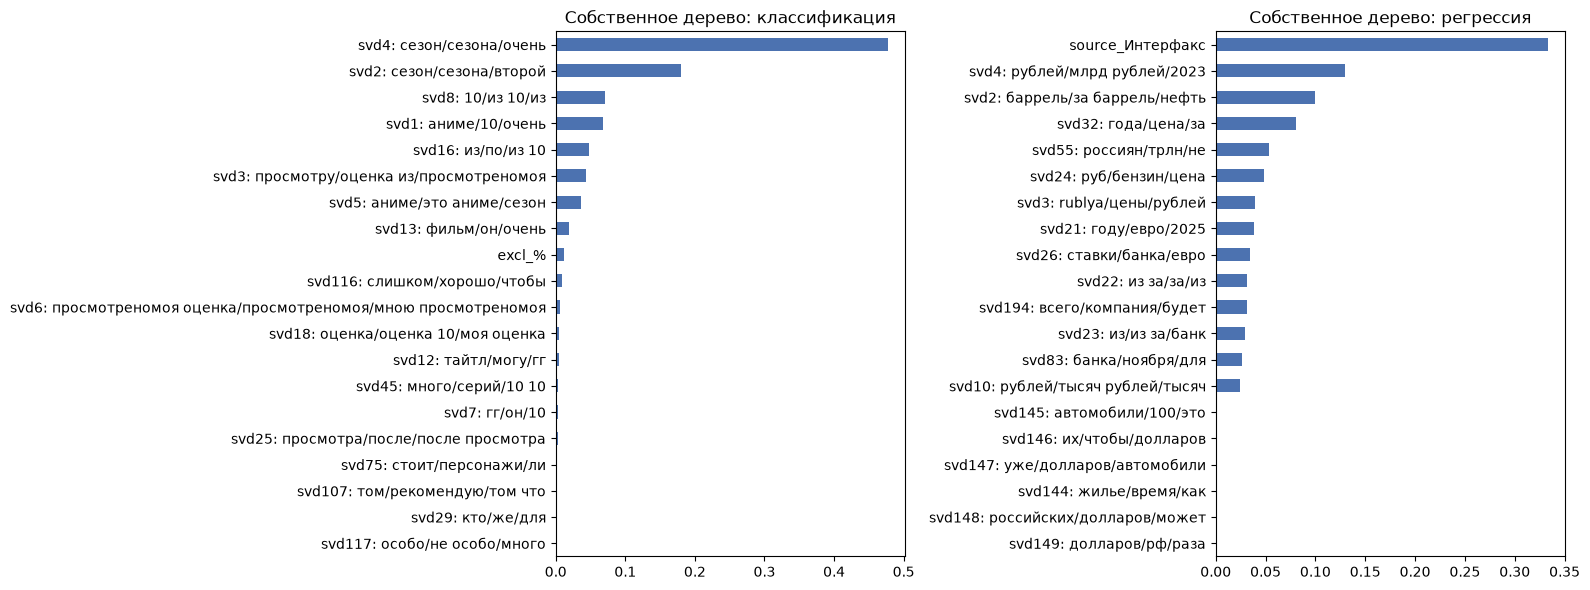

In [19]:
# Важность признаков собственного дерева (накопленный выигрыш разбиений) - сравнение с sklearn
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_importance(my_c2.tree_.feature_importances_, names_c, "Собственное дерево: классификация", ax=ax[0])
plot_importance(my_r2.tree_.feature_importances_, names_r, "Собственное дерево: регрессия", ax=ax[1])
plt.tight_layout(); plt.show()

### 4.10 Выводы

С ограничениями и признаками улучшенного бейзлайна собственное дерево даёт macro-F1 **0.469** (sklearn 0.472) и MAE **32.47**. Регрессионное дерево sklearn здесь использует `absolute_error` (MAE 31.67), а собственное умеет только квадратичный критерий - поэтому у собственного MAE хуже, но R2 выше (0.055 против 0.016). При одинаковом критерии (squared_error) собственное дерево совпадает со sklearn (CV-кривые и проверочная ячейка выше). Важности признаков у двух реализаций совпадают по составу лидеров.

## Сравнение всех этапов

Сводная таблица метрик на тестовой выборке: бейзлайн (п.2), улучшенный бейзлайн (п.3), собственная реализация (п.4) и собственная реализация с техниками улучшенного бейзлайна.

In [20]:
# Таблица метрик по всем этапам и сохранение в labs/results/LR3.json для итогового ноутбука
table = results_table(res)
save_results("LR3", res)
table

,задача,этап,f1_macro,accuracy,mae,rmse,r2
0,classification,baseline,0.3914,0.4027,NaN,NaN,NaN
1,classification,improved,0.4715,0.4857,NaN,NaN,NaN
2,classification,custom,0.3930,0.4033,NaN,NaN,NaN
3,classification,custom_improved,0.4690,0.4905,NaN,NaN,NaN
4,regression,baseline,NaN,NaN,40.299,55.451,-0.6901
5,regression,improved,NaN,NaN,31.671,42.307,0.0162
6,regression,custom,NaN,NaN,40.291,55.351,-0.6840
7,regression,custom_improved,NaN,NaN,32.469,41.458,0.0553


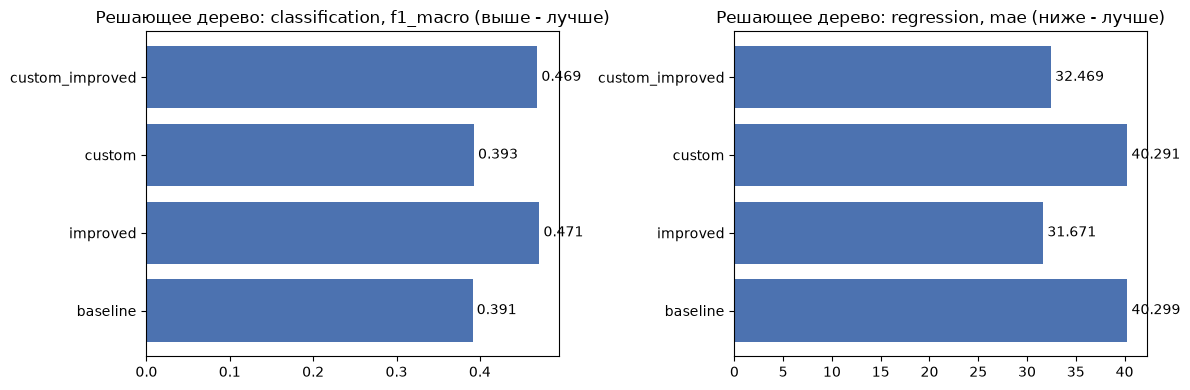

In [21]:
# Визуальное сравнение основной метрики каждой задачи по этапам
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (task, metric) in zip(ax, [("classification", "f1_macro"), ("regression", "mae")]):
    t = table[table["задача"] == task]
    a.barh(t["этап"], t[metric], color="#4C72B0")
    a.set_title(f"Решающее дерево: {task}, {metric}" + (" (выше - лучше)" if metric == "f1_macro" else " (ниже - лучше)"))
    for i, v in enumerate(t[metric]):
        a.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()

## Выводы

1. Одиночное дерево - **самый слабый алгоритм** в обеих задачах (macro-F1 0.47, R2 ~ 0.02-0.06): кусочно-постоянная аппроксимация плохо подходит для текстовых данных.
2. Без ограничения глубины дерево переобучается до качества хуже константы; подбор `max_depth`/`min_samples_leaf` и плотные LSA-признаки - обязательные условия.
3. Собственная гистограммная реализация совпадает со sklearn по качеству и важностям и служит основой для леса (ЛР4) и бустинга (ЛР5).